# Bluesky API Report: Celebrity posts and engagement

Name: Christian Anderson
Date: 09/23/26

**Research question:** Is there a relationship between likes and replies on Bluesky posts mentioning celebrities?

**Hypothesis:** Bluesky posts mentioning celebrities that receive more likes will also receive more replies.

The data source is Bluesky's public API. I will collect recent public posts returned by Bluesky searches for celebrity-related keywords. I will combine the results, remove duplicate posts, and analyze the relationship between likes and replies. main variables will be Like count, reply count, and repost count.

In [3]:
import requests
import pandas as pd

In [36]:
url = "https://api.bsky.app/xrpc/app.bsky.feed.searchPosts"

response = requests.get(url, params={
    "q": "celebrity",
    "sort": "top",
    "limit": 50
})

print(response.status_code)



200


In [37]:
data = response.json()
posts = data["posts"]
print("Number of posts:", len(posts))

Number of posts: 50


In [38]:
print(posts[0])

{'uri': 'at://did:plc:jiunyrpvht5r3gwy6tnag2zu/app.bsky.feed.post/3myb2jdbysk2s', 'cid': 'bafyreieplekt3yge2nxqii353ftbtbesy4hpt4ayjgrrwcbumhklny7324', 'author': {'did': 'did:plc:jiunyrpvht5r3gwy6tnag2zu', 'handle': 'bizabizow.bsky.social', 'displayName': 'Bizabizow / Ty', 'avatar': 'https://cdn.bsky.app/img/avatar/plain/did:plc:jiunyrpvht5r3gwy6tnag2zu/bafkreie753yy7inrf3mchigha624fgqbryptwbxy2jt3znjuqrjervugee', 'associated': {'activitySubscription': {'allowSubscriptions': 'followers'}}, 'labels': [], 'createdAt': '2023-08-18T16:36:34.580Z'}, 'record': {'$type': 'app.bsky.feed.post', 'createdAt': '2026-10-19T21:23:04.455Z', 'embed': {'$type': 'app.bsky.embed.images', 'images': [{'alt': '', 'aspectRatio': {'height': 4000, 'width': 3000}, 'image': {'$type': 'blob', 'ref': {'$link': 'bafkreifmeaaxzpdvoje6e6wsqc7pmllnbcvhqvtayv5whphnvizq3emcwq'}, 'mimeType': 'image/jpeg', 'size': 1875780}}]}, 'langs': ['en'], 'text': 'Met a celebrity today'}, 'embed': {'images': [{'thumb': 'https://cdn.b

In [39]:
post_data = []

for post in posts:
    post_data.append({
        "text": post["record"]["text"],
        "likes": post["likeCount"],
        "replies": post["replyCount"],
        "reposts": post["repostCount"]
    })

df = pd.DataFrame(post_data)
df.head()

,text,likes,replies,reposts
0,Met a celebrity today,730,20,68
1,Our most precious un-media trained celebrity.,617,17,52
2,"That cunt Matt Hancock got £300,000 for I'm A ...",195,9,28
3,posing with my favorite celebrity (first brisk...,542,17,0
4,met a celebrity today,56,1,1


In [40]:
print(len(df))

50


In [41]:
df[["likes", "replies"]].describe()

,likes,replies
count,50.000000,50.000000
mean,107.280000,5.020000
std,152.714091,7.630471
min,6.000000,0.000000
25%,30.000000,1.250000
50%,55.500000,2.000000
75%,95.500000,5.000000
max,730.000000,46.000000


<Axes: title={'center': 'Likes vs. Replies on Celebrity Posts'}, xlabel='likes', ylabel='replies'>

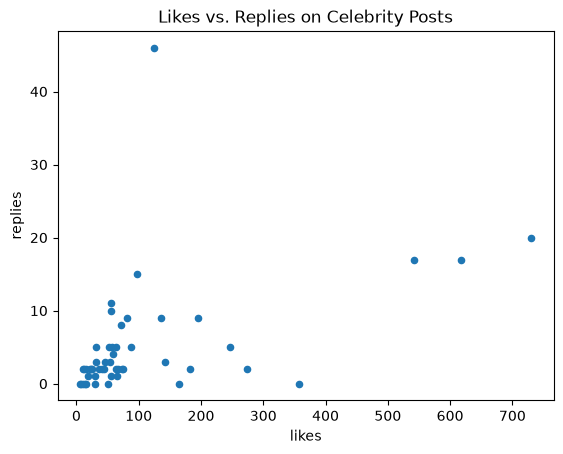

In [42]:
df.plot(kind="scatter", x="likes", y="replies", title="Likes vs. Replies on Celebrity Posts")

In [43]:
df["likes"].corr(df["replies"])

np.float64(0.45215920077127897)

In [44]:
df["text"]

0                                 Met a celebrity today
1         Our most precious un-media trained celebrity.
2     That cunt Matt Hancock got £300,000 for I'm A ...
3     posing with my favorite celebrity (first brisk...
4                                 met a celebrity today
5                #ShitBirdPhotos \n\nCelebrity edition.
6     celebrity\ncharacters from: www.aghoststorycom...
7                                       met a celebrity
8                                 met a celebrity today
9     The Celebrity Traitors finale is 1 hour 20 min...
10                              Encountered a celebrity
11    I just misread Celebrity Traitors as Celebrity...
12            niche micro-celebrity who plays with toys
13    I get instant fatigue from celebrity-endorsed ...
14    Honestly, I think every team should have a cel...
15    When you accidentally pull your celebrity crus...
16    She is, as is appropriate, a minor celebrity w...
17                                      Met a ce


Endpoint 1

I used the Bluesky search posts endpoint to find posts that mentioned the word "celebrity." I collected the top 50 results and looked at each post's likes, replies, and reposts. I used this information to build a DataFrame and see whether posts with more likes also got more replies. One limitation is that not every post was actually about a celebrity, and the top search results might not represent everything people post on Bluesky.


Endpoint 2 

I also used the get post thread endpoint to look at a post and its replies. This helped me see more of the conversation around a post instead of only looking at its engagement numbers. Some posts might not have many replies, so there might not be much to look at. This endpoint also only shows the conversation information returned by the API, so it might not include every reply.


In [46]:
post = posts[0]

post_uri = post["uri"]

thread_url = "https://api.bsky.app/xrpc/app.bsky.feed.getPostThread"

thread_response = requests.get(
    thread_url,
    params={"uri": post_uri}
)

print(thread_response.status_code)

200


In [47]:
thread_data = thread_response.json()

print(thread_data.keys())

dict_keys(['thread'])


In [48]:
thread = thread_data["thread"]

print(thread.keys())

dict_keys(['post', 'replies', 'threadContext', '$type'])


In [49]:
print("Post text:", thread["post"]["record"]["text"])
print("Number of replies returned:", len(thread["replies"]))

Post text: Met a celebrity today
Number of replies returned: 20


In [53]:
replies_data = []

for reply in thread["replies"]:
    replies_data.append({
        "reply_text": reply["post"]["record"]["text"],
        "likes": reply["post"]["likeCount"]
    })

replies_df = pd.DataFrame(replies_data)

replies_df.head()

,reply_text,likes
0,Do you think it contains his essence?,2
1,"Didn't know the song was meant to be literal, ...",0
2,Raise a glass to it,0
3,FREE DOMS?,43
4,how did they wash the blood off,8


In [55]:
replies_df = replies_df.rename(columns={"reply_text": "text"})

df["source"] = "Search posts"
replies_df["source"] = "Conversation replies"

combined_df = pd.concat([df, replies_df], ignore_index=True)

combined_df.head()

,text,likes,replies,reposts,source
0,Met a celebrity today,730,20.0,68.0,Search posts
1,Our most precious un-media trained celebrity.,617,17.0,52.0,Search posts
2,"That cunt Matt Hancock got £300,000 for I'm A ...",195,9.0,28.0,Search posts
3,posing with my favorite celebrity (first brisk...,542,17.0,0.0,Search posts
4,met a celebrity today,56,1.0,1.0,Search posts


In [56]:
df_sorted = df.sort_values(by="likes", ascending=False)

df_sorted.head()

,text,likes,replies,reposts,source
0,Met a celebrity today,730,20,68,Search posts
1,Our most precious un-media trained celebrity.,617,17,52,Search posts
3,posing with my favorite celebrity (first brisk...,542,17,0,Search posts
24,McConaughey for office? Talarico says he'd be ...,358,0,0,Search posts
48,met a celebrity today,274,2,67,Search posts


I sorted the posts by likes from highest to lowest to see which posts received the most engagement. The post with the most likes had 730, followed by posts with 617 and 542 likes.


In [54]:
print("Total replies collected:", len(replies_df))
print("Average likes on replies:", replies_df["likes"].mean())
print("Most likes on a reply:", replies_df["likes"].max())

Total replies collected: 20
Average likes on replies: 7.0
Most likes on a reply: 43


The second endpoint returned 20 replies for the post I selected. The replies had an average of 7 likes, and the most liked reply had 43 likes. This shows the engagement in one conversation, but the results only represent one post and its returned replies, so it does not represent all conversations on Bluesky.

In [52]:
print("Number of posts:", len(df))
print("Correlation:", df["likes"].corr(df["replies"]))

Number of posts: 50
Correlation: 0.45215920077127897



## Results

I looked at 50 Bluesky posts that came up when I searched for "celebrity." On average, the posts had about 107 likes and 5 replies. The correlation between likes and replies was 0.452, which means there was a positive relationship between them. This shows that posts with more likes also tend to have more replies, but not for every post. This supports my hypothesis, but it doesn't mean that more likes cause more replies.


## Limitations

One limitation is that I only looked at 50 posts, so my results will not represent all of Bluesky. I searched for the word "celebrity," but some posts weren't really about celebrities. I also used the top search results, so I may have missed other posts that could have impacted my results. For the second endpoint, I only looked at replies to one post. If I did this project again, I would collect more posts and look at more conversations to see if I got similar results.

## Conclusion

Based on my results, my hypothesis was supported because posts with more likes generally also had more replies. The correlation showed that there was a connection between the two in the 50 posts I looked at. However, I would need to look at more posts to know if the same thing happens across Bluesky.